# Densidades kernel do PIB per capita relativo dos estados brasileiros, 2002, 2012 e 2023

Estima densidades kernel (Epanechnikov) do logaritmo do PIB per capita dos estados em relação ao do Brasil, com a janela da regra de Silverman e janelas alternativas (seção 4.4.1 do TCC).

Os dados vêm do Ipeadata e devem estar na pasta `../dados_usados` (ver o README do repositório).

In [1]:
# ----------------------------------------------------------------------------
# 1. BIBLIOTECAS E PARÂMETROS
# ----------------------------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# As séries do Brasil e do deflator vêm do Ipeadata em formato .xls (Excel antigo).
# O pandas só lê esse formato com o pacote xlrd. Se ele não estiver instalado,
# a linha abaixo o instala automaticamente (é preciso estar conectado à internet).
import importlib.util, subprocess, sys
if importlib.util.find_spec("xlrd") is None:
    print("Pacote xlrd não encontrado; instalando...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xlrd>=2.0.1"])
    importlib.invalidate_caches()

import statsmodels.api as sm
from statsmodels.sandbox.nonparametric import kernels   # constantes de cada kernel

# O notebook fica na pasta QUAH; os dados, em TCC\dados_usados
PASTA_DADOS  = os.path.join("..", "dados_usados")
ARQ_ESTADOS  = os.path.join(PASTA_DADOS, "PIBPCE_pib_estadual_per_capita_precos_2010_[17-08-2026].csv")
ARQ_BRASIL   = os.path.join(PASTA_DADOS, "GAC_PIBCAPN_pib_per_capita_brasil_nominal_[04-11-2026].xls")
ARQ_DEFLATOR = os.path.join(PASTA_DADOS, "SCN10_DIPIBG10_deflator_implicito_pib_[04-11-2026].xls")

ANO_INICIAL = 2002
ANO_FINAL   = 2023
ANO_BASE    = 2010                          # preços de 2010, como a série estadual
ANOS_KERNEL = [2002, 2012, 2023]

CORTES_FIXOS   = [0.5, 0.75, 1.0, 1.5]      # limites das faixas do Markov (renda relativa)
MULT_JANELAS   = [0.5, 1.0, 1.5]            # curvas em cada painel: 0,5h, h e 1,5h
GRADE          = np.linspace(-2.1, 2.1, 841)  # pontos do eixo x em que a densidade é calculada

for pasta in ["resultados/figuras", "resultados/tabelas"]:
    os.makedirs(pasta, exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
pd.set_option("display.width", 160)

In [2]:
# ----------------------------------------------------------------------------
# 2. LEITURA DOS DADOS E RENDA RELATIVA AO BRASIL (mesmo procedimento do notebook do Quah)
# ----------------------------------------------------------------------------
df = pd.read_csv(ARQ_ESTADOS, skiprows=1, encoding="utf-8-sig")
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
anos = [c for c in df.columns if c.isdigit()]
largo = df.set_index("Sigla")[anos].astype(float)
largo.columns = largo.columns.astype(int)
assert largo.shape == (27, 22), f"Esperado 27 UF x 22 anos, obtido {largo.shape}"
assert largo.isna().sum().sum() == 0, "Há valores ausentes"


def ler_serie_ipeadata(caminho):
    """Lê uma série anual exportada do Ipeadata (.xls): coluna Data + coluna de valores."""
    x = pd.read_excel(caminho, header=0)
    x.columns = ["ano", "valor"]
    x = x[x["ano"].astype(str).str.fullmatch(r"\d{4}")]
    return pd.Series(x["valor"].astype(float).values, index=x["ano"].astype(int).values)


brasil_nominal = ler_serie_ipeadata(ARQ_BRASIL)       # R$ mil correntes
deflator_var   = ler_serie_ipeadata(ARQ_DEFLATOR)     # variação anual, % a.a.

# Índice do deflator com 2010 = 1
indice = {ANO_BASE: 1.0}
for t in range(ANO_BASE + 1, ANO_FINAL + 1):
    indice[t] = indice[t - 1] * (1 + deflator_var[t] / 100)
for t in range(ANO_BASE, ANO_INICIAL, -1):
    indice[t - 1] = indice[t] / (1 + deflator_var[t] / 100)
indice = pd.Series(indice).sort_index().loc[ANO_INICIAL:ANO_FINAL]
brasil_real = brasil_nominal.loc[ANO_INICIAL:ANO_FINAL] / indice     # R$ mil de 2010

# Renda relativa (x = y / Y) e seu logaritmo
relativa = largo.div(brasil_real, axis=1)
ln_rel   = np.log(relativa)

tab_dados = pd.DataFrame({f"{a} relativa": relativa[a] for a in ANOS_KERNEL})
for a in ANOS_KERNEL:
    tab_dados[f"{a} ln"] = ln_rel[a]
tab_dados = tab_dados.sort_values(f"{ANOS_KERNEL[0]} ln")
print("Renda relativa ao Brasil e seu logaritmo, por estado (ordenado por 2002):")
print(tab_dados.to_string())

Renda relativa ao Brasil e seu logaritmo, por estado (ordenado por 2002):
       2002 relativa  2012 relativa  2023 relativa  2002 ln  2012 ln  2023 ln
Sigla                                                                        
PI             0.288          0.368          0.460   -1.243   -0.999   -0.777
MA             0.322          0.365          0.410   -1.133   -1.008   -0.891
PB             0.428          0.451          0.453   -0.849   -0.796   -0.793
CE             0.440          0.457          0.490   -0.820   -0.784   -0.713
AL             0.469          0.444          0.535   -0.757   -0.813   -0.626
PA             0.482          0.558          0.581   -0.731   -0.584   -0.543
TO             0.518          0.591          0.788   -0.659   -0.526   -0.238
BA             0.518          0.522          0.567   -0.657   -0.650   -0.567
PE             0.523          0.581          0.555   -0.647   -0.544   -0.588
RN             0.558          0.583          0.573   -0.583   -0.540

In [3]:
# ----------------------------------------------------------------------------
# 3. JANELA (h): regra de Silverman, convertida para a Epanechnikov, média dos três anos
# ----------------------------------------------------------------------------
# Fator de conversão gaussiana -> Epanechnikov, a partir das constantes de referência
# normal que o próprio statsmodels usa para cada kernel (C_epa ≈ 2,345; C_gau ≈ 1,059).
C_EPA = kernels.Epanechnikov().normal_reference_constant
C_GAU = kernels.Gaussian().normal_reference_constant
FATOR = C_EPA / C_GAU


def janela_silverman(x):
    """Regra de bolso de Silverman: 0,9 · min(desvio-padrão, AIQ/1,349) · n^(-1/5)."""
    x = np.asarray(x)
    dp  = x.std(ddof=1)
    aiq = np.subtract(*np.percentile(x, [75, 25]))
    A   = min(dp, aiq / 1.349)
    return 0.9 * A * len(x) ** (-0.2), dp, aiq / 1.349, A


def tabela_janelas(dados_ln, rotulo):
    linhas = []
    for a in ANOS_KERNEL:
        h_gau, dp, aiq_esc, A = janela_silverman(dados_ln[a])
        linhas.append({"Amostra": rotulo, "Ano": a, "n": dados_ln.shape[0],
                       "Desvio-padrão": dp, "AIQ/1,349": aiq_esc, "A (menor)": A,
                       "h Silverman (gaussiano)": h_gau,
                       "h convertido (Epanechnikov)": h_gau * FATOR})
    tab = pd.DataFrame(linhas)
    h_unica = tab["h convertido (Epanechnikov)"].mean()
    return tab, h_unica


janelas_27, H_27 = tabela_janelas(ln_rel, "27 UF")
janelas_26, H_26 = tabela_janelas(ln_rel.drop(index="DF"), "Sem o DF")

print(f"Fator de conversão gaussiana -> Epanechnikov: {C_EPA:.4f} / {C_GAU:.4f} = {FATOR:.4f}\n")
print(pd.concat([janelas_27, janelas_26]).to_string(index=False))
print(f"\nJanela única usada (média dos três anos convertidos):")
print(f"  27 UF:    h = {H_27:.3f}   -> curvas com 0,5h = {0.5*H_27:.3f}, h = {H_27:.3f}, 1,5h = {1.5*H_27:.3f}")
print(f"  sem o DF: h = {H_26:.3f}   -> curvas com 0,5h = {0.5*H_26:.3f}, h = {H_26:.3f}, 1,5h = {1.5*H_26:.3f}")

Fator de conversão gaussiana -> Epanechnikov: 2.3449 / 1.0592 = 2.2138

 Amostra  Ano  n  Desvio-padrão  AIQ/1,349  A (menor)  h Silverman (gaussiano)  h convertido (Epanechnikov)
   27 UF 2002 27          0.510      0.446      0.446                    0.208                        0.460
   27 UF 2012 27          0.475      0.486      0.475                    0.221                        0.489
   27 UF 2023 27          0.442      0.499      0.442                    0.206                        0.455
Sem o DF 2002 26          0.435      0.406      0.406                    0.190                        0.421
Sem o DF 2012 26          0.418      0.470      0.418                    0.196                        0.434
Sem o DF 2023 26          0.389      0.481      0.389                    0.183                        0.404

Janela única usada (média dos três anos convertidos):
  27 UF:    h = 0.468   -> curvas com 0,5h = 0.234, h = 0.468, 1,5h = 0.702
  sem o DF: h = 0.420   -> curvas com 0,5

In [4]:
# ----------------------------------------------------------------------------
# 4. ESTIMAÇÃO DAS DENSIDADES
# ----------------------------------------------------------------------------
def densidade(x, h):
    """Densidade kernel Epanechnikov com janela h fixa, calculada nos pontos de GRADE."""
    x = np.asarray(x, dtype=float)
    kde = sm.nonparametric.KDEUnivariate(x)
    kde.fit(kernel="epa", bw=h, fft=False)      # fft só funciona com o kernel gaussiano
    # evaluate() calcula um ponto por vez; longe de todos os estados (densidade zero)
    # o statsmodels devolve nan, que aqui vira 0
    f = np.array([np.nan_to_num(np.ravel(kde.evaluate(p))[0]) for p in GRADE])
    # Conferência com a fórmula f(x) = 1/(n h) · Σ 3/4 (1 − u²), u = (x − X_i)/h, |u| ≤ 1
    u = (GRADE[:, None] - x[None, :]) / h
    f_formula = (0.75 * (1 - u**2) * (np.abs(u) <= 1)).sum(axis=1) / (len(x) * h)
    assert np.allclose(f, f_formula, atol=1e-10), "statsmodels difere da fórmula"
    return f


def estimar(dados_ln, h):
    dens = {}
    for a in ANOS_KERNEL:
        for m in MULT_JANELAS:
            dens[(a, m)] = densidade(dados_ln[a], m * h)
    return dens


dens_27 = estimar(ln_rel, H_27)
dens_26 = estimar(ln_rel.drop(index="DF"), H_26)

# Checagem: a área sob cada curva deve ser 1 (a grade cobre todos os estados com folga)
passo = GRADE[1] - GRADE[0]
for nome, dens in [("27 UF", dens_27), ("sem o DF", dens_26)]:
    areas = [d.sum() * passo for d in dens.values()]
    print(f"{nome}: área sob as curvas entre {min(areas):.4f} e {max(areas):.4f}")

27 UF: área sob as curvas entre 1.0000 e 1.0000
sem o DF: área sob as curvas entre 1.0000 e 1.0000


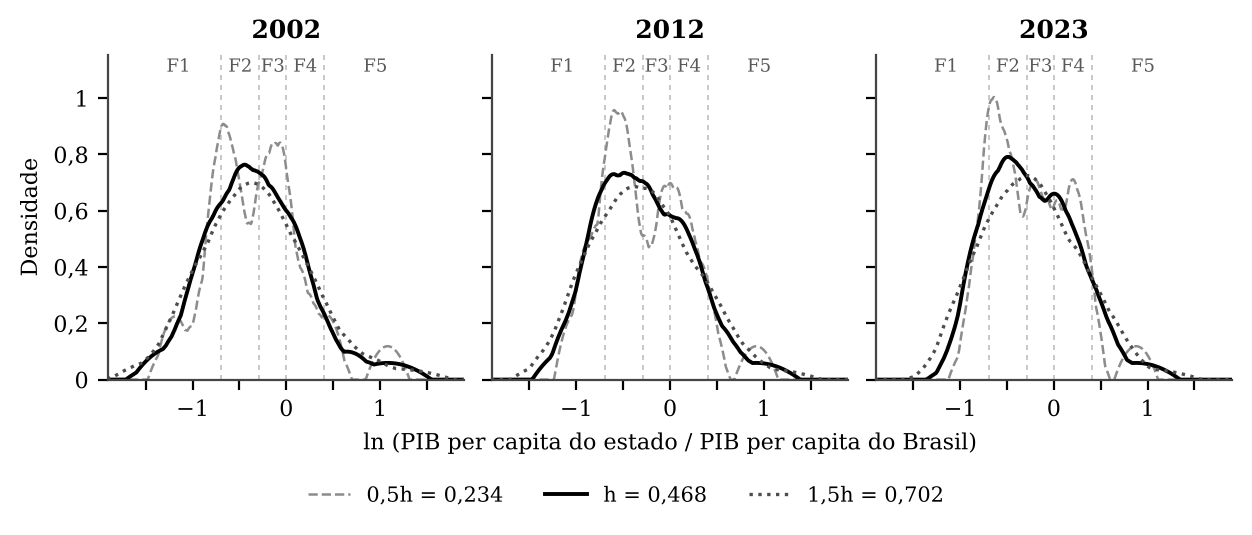

Sugestão de legenda (padrão do modelo):
  Figura X – Densidade kernel do logaritmo do PIB per capita dos estados em relação ao
  PIB per capita do Brasil, 2002, 2012 e 2023
  Fonte: elaborada a partir dos dados da pesquisa.


In [5]:
# ----------------------------------------------------------------------------
# 5. FIGURA: três painéis lado a lado (2002, 2012 e 2023) — Figura 7 do trabalho escrito
# ----------------------------------------------------------------------------
# Padrão das figuras do texto: preto e cinza, fonte serifada, vírgula decimal, sem título
# (título e fonte ficam no Word), no tamanho de impressão (16 cm = 6,3 pol. de largura).
virgula = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",").replace("-", "−"))
ESTILOS = {0.5: dict(color="0.55", ls="--", lw=0.9),
           1.0: dict(color="black", ls="-", lw=1.4),
           1.5: dict(color="0.30", ls=":", lw=1.2)}
LIMITES_LN = np.log(CORTES_FIXOS)
# posição dos rótulos F1 a F5 (no meio de cada faixa, em ln)
POS_FAIXAS = [-1.15, np.mean(LIMITES_LN[0:2]), np.mean(LIMITES_LN[1:3]),
              np.mean(LIMITES_LN[2:4]), 0.95]


def figura(dados_ln, dens, h, arquivo):
    ymax = max(d.max() for d in dens.values()) * 1.15
    with plt.rc_context({"font.family": "serif", "font.size": 8, "axes.spines.top": False,
                         "axes.spines.right": False, "axes.edgecolor": "#444444"}):
        fig, eixos = plt.subplots(1, len(ANOS_KERNEL), figsize=(6.3, 2.6), sharey=True)
        for ax, a in zip(eixos, ANOS_KERNEL):
            for m in MULT_JANELAS:
                rot = {0.5: "0,5h", 1.0: "h", 1.5: "1,5h"}[m]
                ax.plot(GRADE, dens[(a, m)], label=f"{rot} = {m*h:.3f}".replace(".", ","),
                        **ESTILOS[m])
            # limites das faixas do Markov (0,50; 0,75; 1; 1,50) e rótulos F1 a F5
            for xl in LIMITES_LN:
                ax.axvline(xl, color="0.75", lw=0.6, ls=(0, (3, 3)), zorder=0)
            for k, xp in enumerate(POS_FAIXAS, start=1):
                ax.text(xp, ymax * 0.99, f"F{k}", ha="center", va="top", fontsize=6.5, color="0.35")
            ax.set_ylim(0, ymax)
            ax.set_xlim(-1.9, 1.9)
            ax.set_xticks([-1.5, -1, -0.5, 0, 0.5, 1, 1.5])
            ax.set_xticklabels(["", "−1", "", "0", "", "1", ""])
            ax.yaxis.set_major_formatter(virgula)
            ax.set_title(str(a), fontsize=9, fontweight="bold")
        eixos[0].set_ylabel("Densidade")
        eixos[1].set_xlabel("ln (PIB per capita do estado / PIB per capita do Brasil)", fontsize=8)
        handles, labels = eixos[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=7.5,
                   bbox_to_anchor=(0.5, -0.02))
        fig.tight_layout(rect=(0, 0.07, 1, 1), w_pad=0.8)
        fig.savefig(os.path.join("resultados", "figuras", arquivo), dpi=300, bbox_inches="tight")
        plt.show()


figura(ln_rel, dens_27, H_27, "kernel_2002_2012_2023.png")

print("Sugestão de legenda (padrão do modelo):")
print("  Figura X – Densidade kernel do logaritmo do PIB per capita dos estados em relação ao")
print("  PIB per capita do Brasil, 2002, 2012 e 2023")
print("  Fonte: elaborada a partir dos dados da pesquisa.")

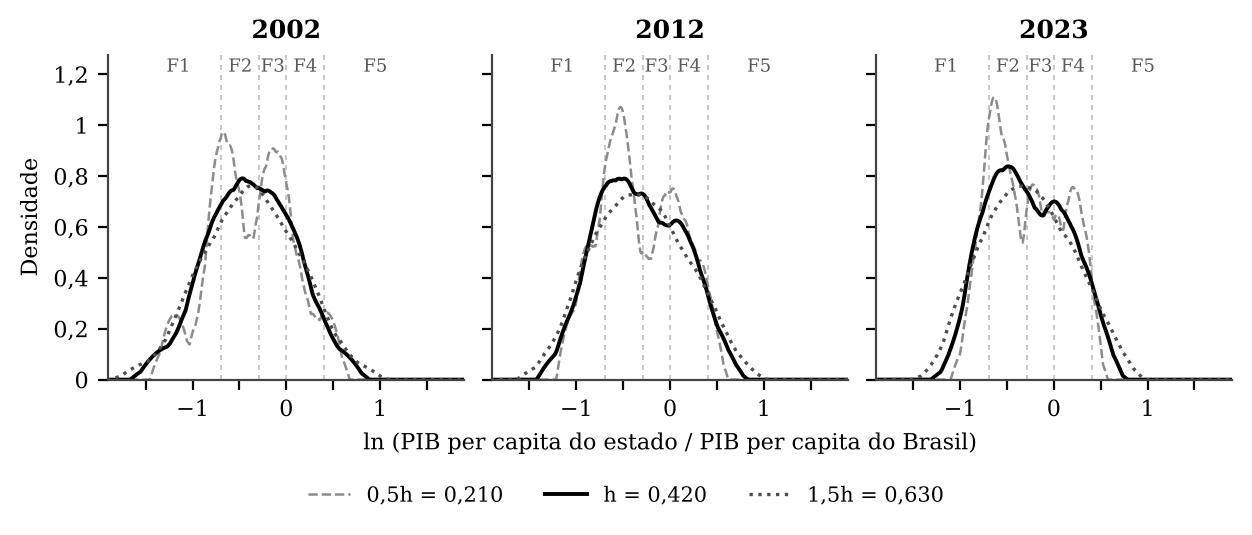

In [6]:
# ----------------------------------------------------------------------------
# 6. ROBUSTEZ: mesma figura sem o DF (janela recalculada com os 26 estados)
# ----------------------------------------------------------------------------
figura(ln_rel.drop(index="DF"), dens_26, H_26, "kernel_2002_2012_2023_sem_df.png")

In [7]:
# ----------------------------------------------------------------------------
# 7. TABELAS SALVAS
# ----------------------------------------------------------------------------
tab_dados.to_csv(os.path.join("resultados", "tabelas", "kernel_renda_relativa_estados.csv"),
                 encoding="utf-8-sig")
pd.concat([janelas_27, janelas_26]).to_csv(
    os.path.join("resultados", "tabelas", "kernel_janelas.csv"), index=False, encoding="utf-8-sig")

grade = pd.DataFrame({"ln_renda_relativa": GRADE})
for nome, dens, h in [("27UF", dens_27, H_27), ("semDF", dens_26, H_26)]:
    for (a, m), d in dens.items():
        grade[f"{nome}_{a}_{m}h"] = d
grade.to_csv(os.path.join("resultados", "tabelas", "kernel_densidades_grade.csv"),
             index=False, encoding="utf-8-sig")
print("Arquivos salvos em resultados/figuras e resultados/tabelas.")

Arquivos salvos em resultados/figuras e resultados/tabelas.
